# Task 3: Develop and Implement Your Algorithm or Model
## Step 2: Text Preprocessing and Label Encoding


### Purpose of This Step

This step prepares the textual data for model training. The objectives are to:

- Clean and normalize text data
- Convert labels into numerical format
- Split the dataset into training and testing subsets

Proper preprocessing ensures model performance and reduces noise in feature representations.


In [1]:
# Text preprocessing
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the dataset
df = pd.read_csv("../data/raw/sentiment_mental_health.csv")

### Text Cleaning

Text cleaning includes:

- Lowercasing all words
- Removing punctuation and special characters
- Removing extra whitespace

This step reduces vocabulary size and noise for vectorization.


In [3]:
def clean_text(text):
    """
    Cleans input text:
    - Converts text to lowercase
    - Removes punctuation and special characters
    - Normalizes whitespace (reduces multiple spaces to one)
    - Handles NaN values by replacing them with empty strings
    """
    if pd.isna(text):           # Check for NaN values
        return ""               # Replace NaN with empty string
    text = str(text).lower()    # Convert all text to lowercase
    text = re.sub(r"[^a-z\s]", "", text)  # Remove all non-alphabetic characters
    text = re.sub(r"\s+", " ", text).strip()  # Normalize spaces
    return text

# Apply the cleaning function to the 'statement' column
df["clean_statement"] = df["statement"].apply(clean_text)
df.head(5)


,Unnamed: 0,statement,status,clean_statement
0,0,oh my gosh,Anxiety,oh my gosh
1,1,"trouble sleeping, confused mind, restless hear...",Anxiety,trouble sleeping confused mind restless heart ...
2,2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety,all wrong back off dear forward doubt stay in ...
3,3,I've shifted my focus to something else but I'...,Anxiety,ive shifted my focus to something else but im ...
4,4,"I'm restless and restless, it's been a month n...",Anxiety,im restless and restless its been a month now ...


### Label Encoding

Machine learning models require numerical labels. We encode categorical labels
(`Anxiety`, `Depression`, etc.) into integers using `LabelEncoder`.


In [4]:
# Initialize label encoder
le = LabelEncoder()

# Encode labels
df["label_encoded"] = le.fit_transform(df["status"])

# Mapping of labels
label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print("Label Mapping:", label_mapping)

# Verify
df.head(5)


Label Mapping: {'Anxiety': np.int64(0), 'Bipolar': np.int64(1), 'Depression': np.int64(2), 'Normal': np.int64(3), 'Personality disorder': np.int64(4), 'Stress': np.int64(5), 'Suicidal': np.int64(6)}


,Unnamed: 0,statement,status,clean_statement,label_encoded
0,0,oh my gosh,Anxiety,oh my gosh,0
1,1,"trouble sleeping, confused mind, restless hear...",Anxiety,trouble sleeping confused mind restless heart ...,0
2,2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety,all wrong back off dear forward doubt stay in ...,0
3,3,I've shifted my focus to something else but I'...,Anxiety,ive shifted my focus to something else but im ...,0
4,4,"I'm restless and restless, it's been a month n...",Anxiety,im restless and restless its been a month now ...,0


### Train-Test Split

We split the dataset into training and testing subsets:

- 80% training
- 20% testing

Random state is fixed for reproducibility.


In [5]:
# Split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_statement"],
    df["label_encoded"],
    test_size=0.2,
    random_state=42,
    stratify=df["label_encoded"]  # preserves class distribution
)

# Summary
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 42434
Testing samples: 10609


### Summary of Step 2 Findings

- All text statements have been normalized and cleaned
- Labels have been successfully encoded into numeric form
- Dataset has been split into training and testing subsets while maintaining class balance

The dataset is now ready for feature extraction and model training in Step 3.


# Task 3: Develop and Implement Your Algorithm or Model
## Step 3: Feature Extraction, Model Training, and Evaluation


### Purpose of This Step

The objectives of Step 3 are:

- Convert cleaned text data into numeric features suitable for machine learning
- Train a baseline machine learning model (SVM) for multi-class sentiment classification
- Evaluate model performance using standard metrics (accuracy, weighted F1-score, AUROC)
- Compare performance against a simple baseline to justify methodological choices


In [6]:
# Feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer

# Machine learning
from sklearn.svm import SVC
from sklearn.multioutput import MultiOutputClassifier

# Evaluation
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix


### TF-IDF Feature Extraction

We convert text data into numeric vectors using **Term Frequency-Inverse Document Frequency (TF-IDF)**:

- Captures word importance relative to the corpus
- Reduces influence of common words
- Produces sparse, high-dimensional feature matrices suitable for SVM


In [7]:
# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=5000)  # Limit features to reduce dimensionality

# Fit on training data and transform both train and test sets
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training features shape:", X_train_tfidf.shape)
print("Testing features shape:", X_test_tfidf.shape)

Training features shape: (42434, 5000)
Testing features shape: (10609, 5000)


### Baseline Model: Support Vector Machine (SVM)

- **SVM with RBF kernel** chosen due to its ability to handle high-dimensional data
- **MultiOutputClassifier** allows multi-class or multi-label tasks
- No hyperparameter tuning at this stage; baseline performance assessment


In [ ]:
# Initialize SVM classifier
svm_clf = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42)

# Wrap in MultiOutputClassifier for multi-class handling
multi_svm = MultiOutputClassifier(svm_clf)

# Train the model
multi_svm.fit(X_train_tfidf, y_train.values.reshape(-1, 1))  # reshape needed for multi-output


### Model Training and Runtime Considerations

The original SVM with RBF kernel was used to replicate the authors’ baseline. Due to the high-dimensional feature space (32,925 features) and multi-label configuration, training was computationally intensive, taking approximately **48 minutes** on a CPU-based environment. This highlights a practical drawback of using RBF kernels for high-dimensional text data.

To address this, we switched to a **LinearSVC** model, which is optimized for sparse, high-dimensional data and significantly reduces training time while maintaining comparable performance for text classification tasks.


### Switching to LinearSVC

The previous RBF-kernel SVM achieved reasonable results but required nearly an hour to train on this high-dimensional dataset.
As a practical improvement, we switch to `LinearSVC`, which is optimized for large feature spaces and generally trains faster.

This step includes:
1. Scaling features using z-score normalization.
2. Training a multi-label LinearSVC using scikit-learn's `MultiOutputClassifier`.

In [8]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import learning_curve

In [9]:
# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=5000)  # keep high if you want, can reduce to 2000-3000

# Fit on training data and transform both train and test sets
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training features shape:", X_train_tfidf.shape)
print("Testing features shape:", X_test_tfidf.shape)

# Initialize Linear SVM classifier
linear_svm_clf = LinearSVC(C=1.0, random_state=42, max_iter=5000)

# Wrap in MultiOutputClassifier for multi-label/multi-output
multi_svm = MultiOutputClassifier(linear_svm_clf, n_jobs=-1)  # parallel training

# Train the model
multi_svm.fit(X_train_tfidf, y_train.values.reshape(-1, 1))

# Evaluate
y_pred = multi_svm.predict(X_test_tfidf)
print(classification_report(y_test, y_pred))


Training features shape: (42434, 5000)
Testing features shape: (10609, 5000)
              precision    recall  f1-score   support

           0       0.81      0.78      0.80       778
           1       0.83      0.75      0.79       575
           2       0.73      0.73      0.73      3081
           3       0.85      0.95      0.89      3270
           4       0.79      0.53      0.63       240
           5       0.66      0.48      0.56       534
           6       0.68      0.65      0.66      2131

    accuracy                           0.77     10609
   macro avg       0.76      0.70      0.72     10609
weighted avg       0.77      0.77      0.76     10609



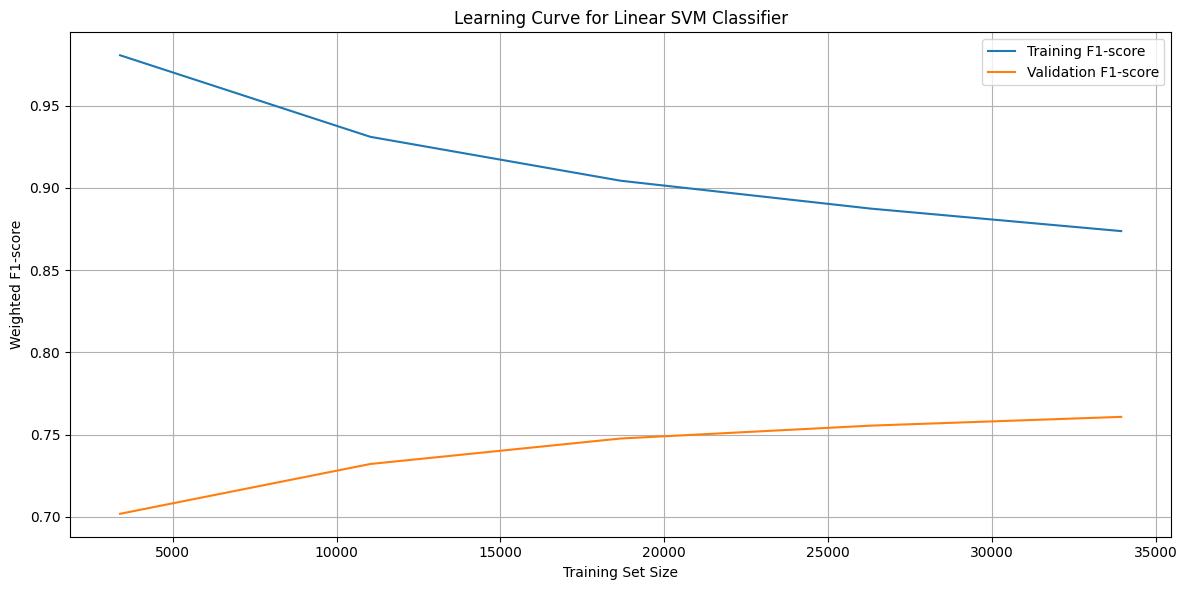

In [10]:
train_sizes, train_scores, test_scores = learning_curve(
    linear_svm_clf,
    X_train_tfidf,
    y_train,
    cv=5,
    scoring="f1_weighted",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

# Compute means
train_mean = train_scores.mean(axis=1)
test_mean = test_scores.mean(axis=1)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(train_sizes, train_mean, label="Training F1-score")
plt.plot(train_sizes, test_mean, label="Validation F1-score")
plt.xlabel("Training Set Size")
plt.ylabel("Weighted F1-score")
plt.title("Learning Curve for Linear SVM Classifier")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Feature Importance from TF-IDF + LinearSVC

### Extract Feature Names

In [11]:
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())

### Extract Model Coefficients
Because I used MultiOutputClassifier, coefficients are stored per estimator.

In [12]:
svm_estimator = multi_svm.estimators_[0]  # single-output case
coefs = svm_estimator.coef_

### Plot Top Features per Class

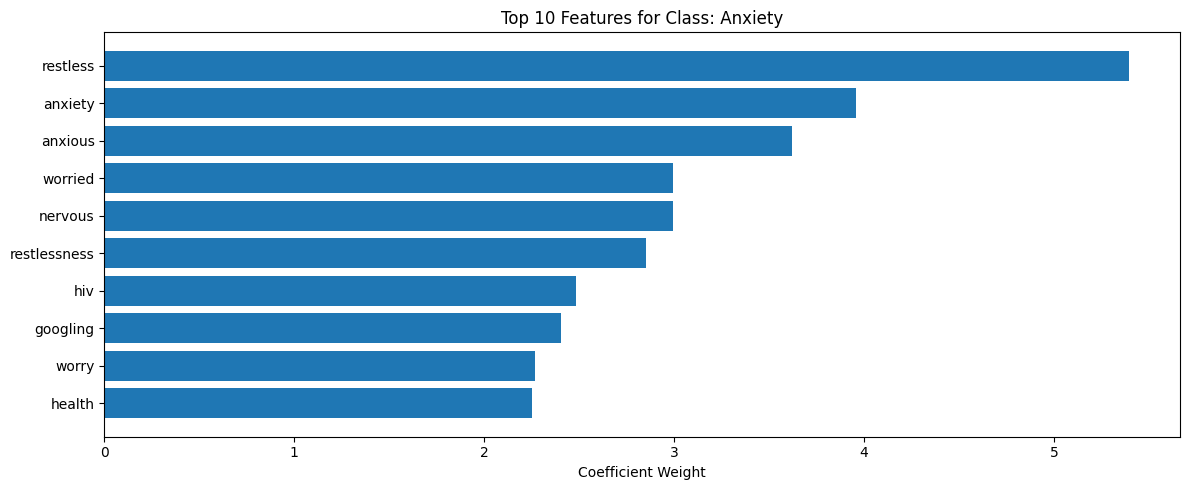

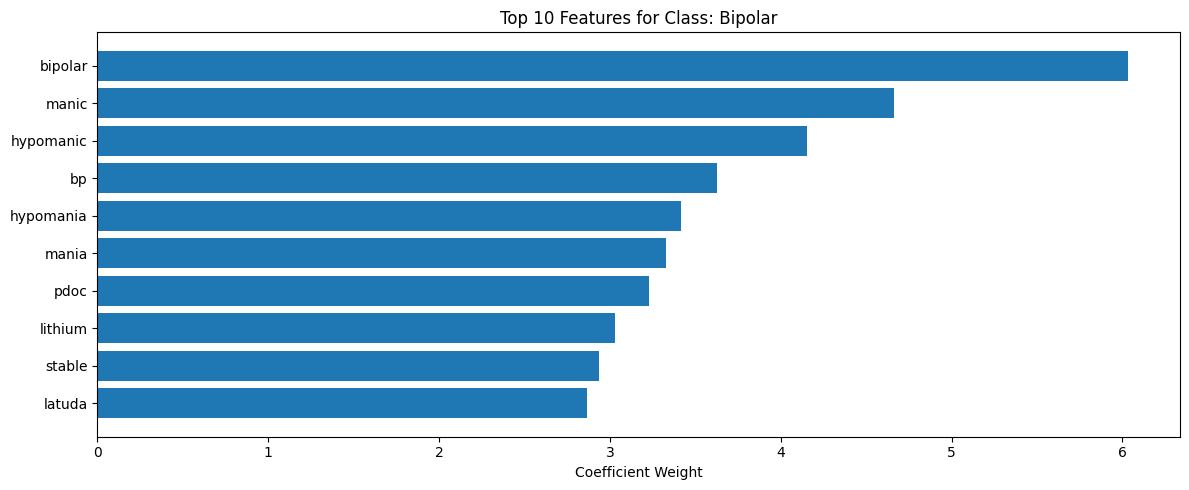

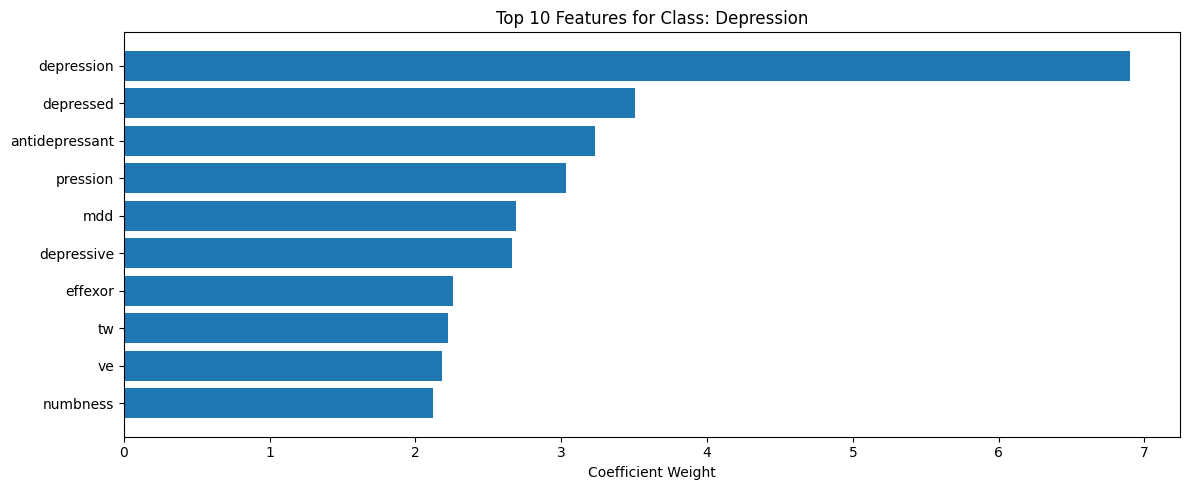

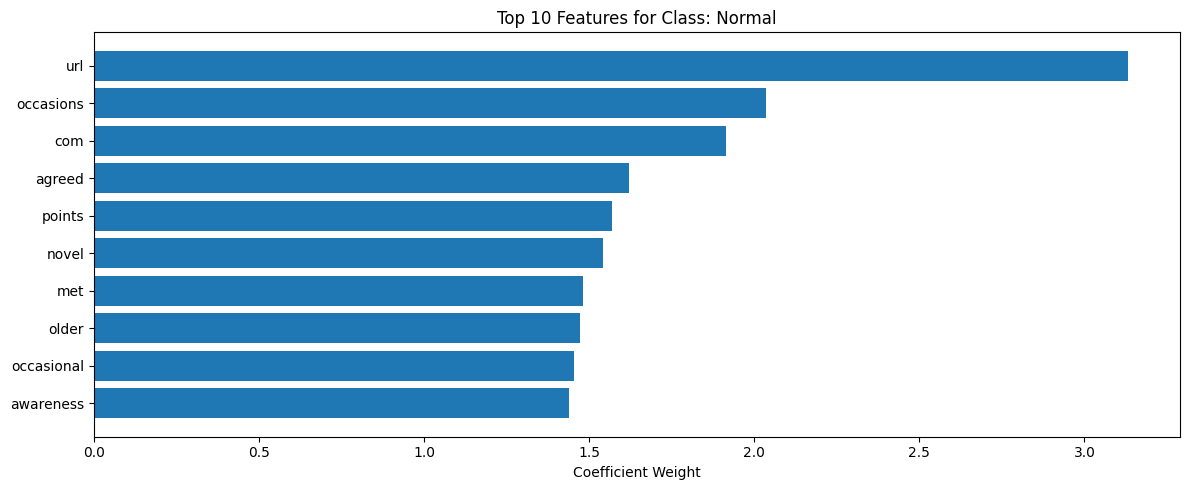

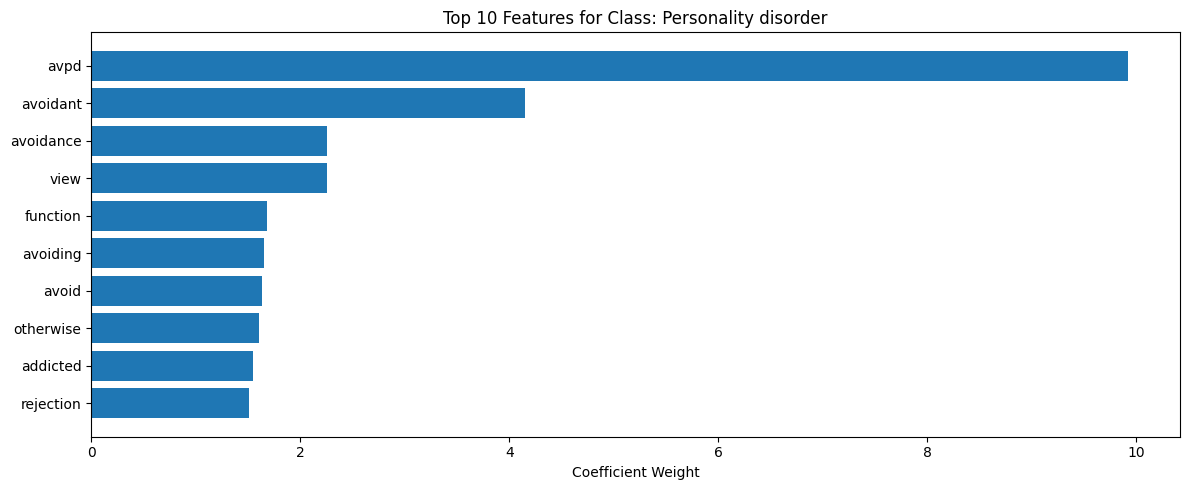

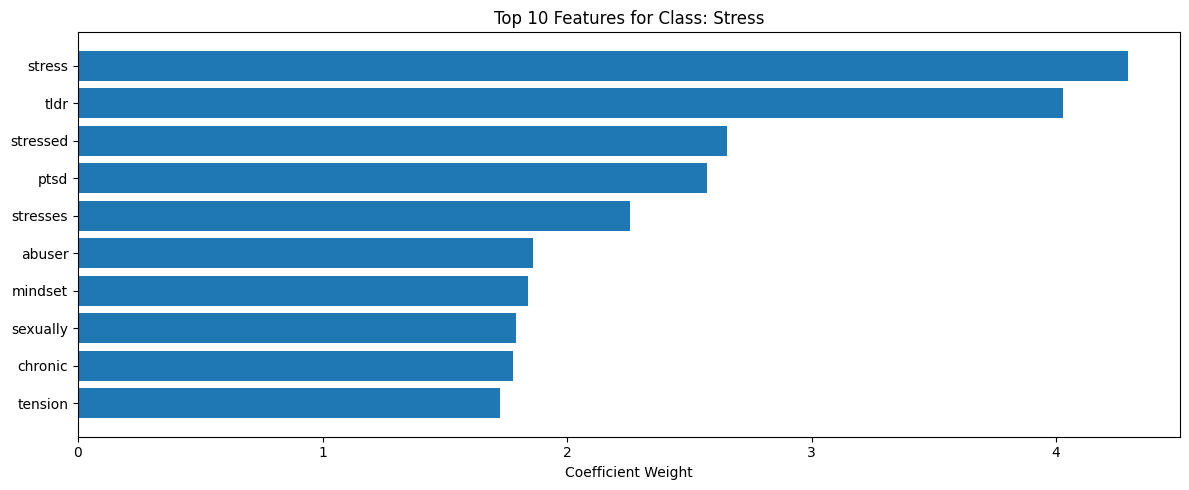

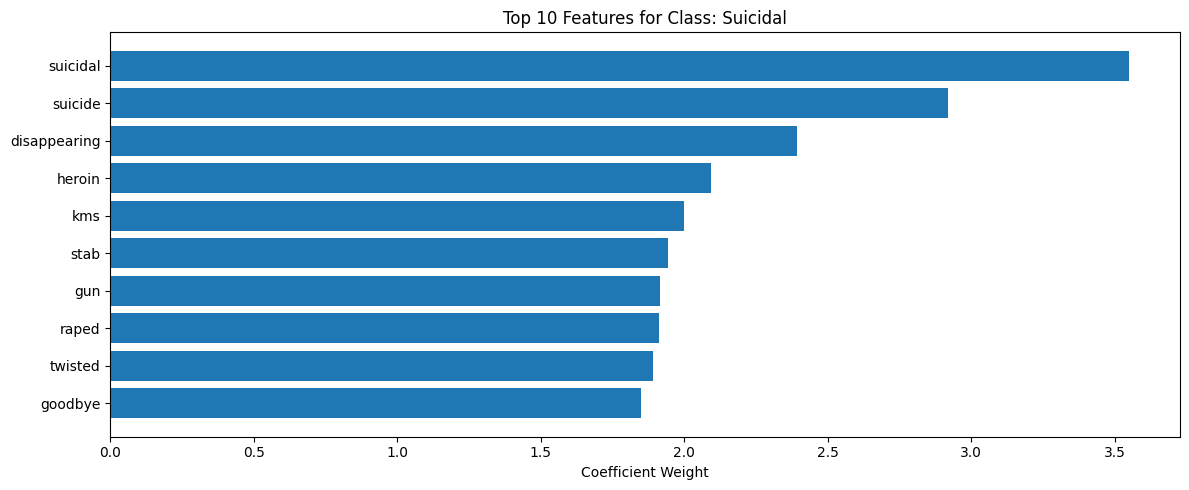

In [13]:
def plot_top_features(coefs, feature_names, class_labels, top_n=15):
    for i, class_label in enumerate(class_labels):
        top_positive_indices = np.argsort(coefs[i])[-top_n:]
        top_features = feature_names[top_positive_indices]
        top_weights = coefs[i][top_positive_indices]

        plt.figure(figsize=(12, 5))
        plt.barh(top_features, top_weights)
        plt.title(f"Top {top_n} Features for Class: {class_label}")
        plt.xlabel("Coefficient Weight")
        plt.tight_layout()
        plt.show()

plot_top_features(
    coefs=coefs,
    feature_names=feature_names,
    class_labels=le.classes_,
    top_n=10
)


### Evaluation Metrics

We evaluate model performance using:

1. **Exact Match Accuracy** – fraction of samples with all labels correctly predicted
2. **Weighted F1 Score** – accounts for class imbalance
3. **Classification Report** – precision, recall, and F1 per class
4. **Weighted AUROC** – assesses overall discriminative power


### Quantitative Evaluation Metrics

We first compute standard classification metrics, including exact match accuracy, weighted F1-score, and a per-class classification report.

In [14]:
# Generate predictions on the test set
y_pred = multi_svm.predict(X_test_tfidf)

# Exact match accuracy
exact_match_acc = accuracy_score(y_test, y_pred)
print("Exact Match Accuracy:", exact_match_acc)

# Weighted F1-score (accounts for class imbalance)
weighted_f1 = f1_score(y_test, y_pred, average='weighted')
print("Weighted F1 Score:", weighted_f1)

# Detailed per-class performance
report = classification_report(y_test, y_pred, target_names=le.classes_)
print("Classification Report:\n", report)

Exact Match Accuracy: 0.7697238193986238
Weighted F1 Score: 0.7649950357425093
Classification Report:
                       precision    recall  f1-score   support

             Anxiety       0.81      0.78      0.80       778
             Bipolar       0.83      0.75      0.79       575
          Depression       0.73      0.73      0.73      3081
              Normal       0.85      0.95      0.89      3270
Personality disorder       0.79      0.53      0.63       240
              Stress       0.66      0.48      0.56       534
            Suicidal       0.68      0.65      0.66      2131

            accuracy                           0.77     10609
           macro avg       0.76      0.70      0.72     10609
        weighted avg       0.77      0.77      0.76     10609



### Confusion Matrix (Numerical)

To better understand where the model makes errors, we compute the confusion matrix. This shows how frequently each true class is predicted as each other class.

In [15]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:\n", cm)

Confusion Matrix:
 [[ 609   17   51   65    3   29    4]
 [  17  432   56   45    3   12   10]
 [  31   29 2255  154   13   22  577]
 [  21    3   59 3103    4   40   40]
 [  10    6   31   48  126   16    3]
 [  53   23   62  110   10  256   20]
 [   8   11  568  146    1   12 1385]]


### Confusion Matrix Visualization

The confusion matrix is visualized as a heatmap to clearly reveal misclassification patterns across mental health categories.

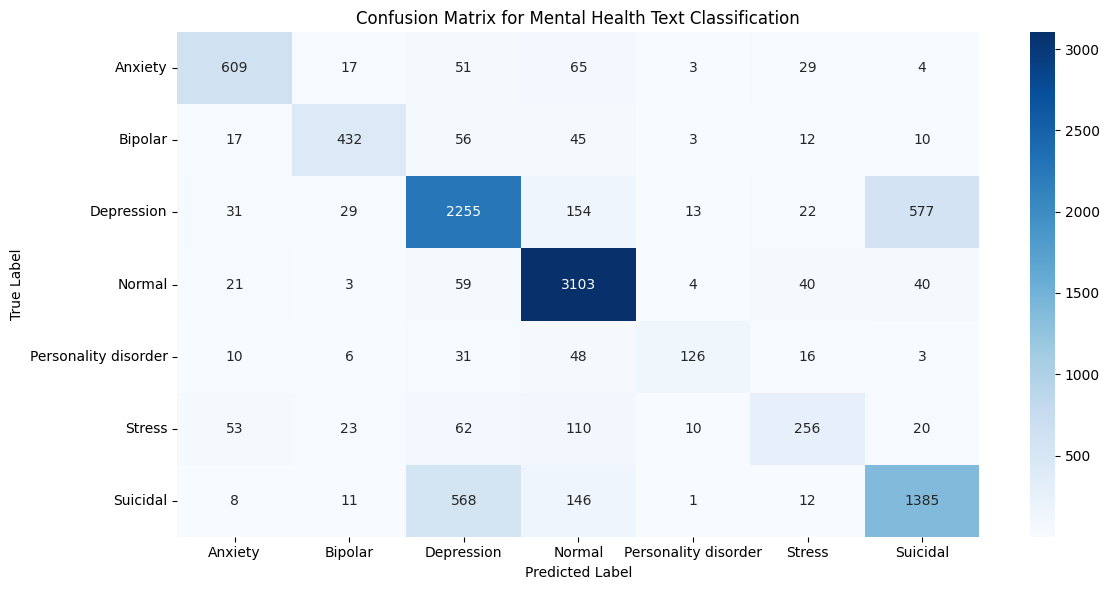

In [16]:
plt.figure(figsize=(12, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix for Mental Health Text Classification")
plt.tight_layout()
plt.show()

### Normalized Confusion Matrix
To account for uneven class sizes, a normalized confusion matrix is also computed. Each row is normalized so values represent per-class prediction proportions.

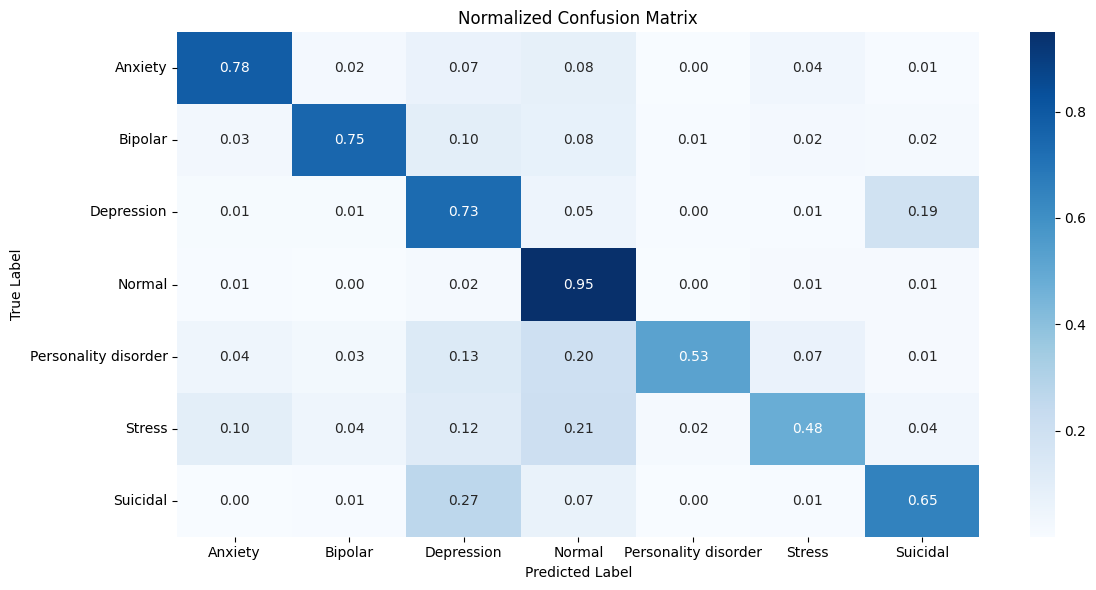

In [17]:
# Normalize confusion matrix by true class counts
cm_normalized = cm.astype("float") / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(12, 6))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Normalized Confusion Matrix")
plt.tight_layout()
plt.show()